<a href="https://colab.research.google.com/github/inesnair/birdsfinder/blob/main/01_europe_10especes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

connection au drive pour y sauvegarder les données (Colab efface tout à la fermeture),récup du code depuis GitHub et instal les bibliothèques train.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!git clone https://github.com/inesnair/birdsfinder.git
%cd birdsfinder
!pip -q install -r requirements-train.txt

Mounted at /content/drive
Cloning into 'birdsfinder'...
remote: Enumerating objects: 4543, done.
remote: Total 4543 (delta 0), reused 0 (delta 0), pack-reused 4543 (from 1)
Receiving objects: 100% (4543/4543), 51.16 MiB | 14.49 MiB/s, done.
Resolving deltas: 100% (1011/1011), done.
/content/birdsfinder


nouveau dossier pour version a 10 especes

In [2]:
DRIVE = "/content/drive/MyDrive/birdsfinder"
OUT = f"{DRIVE}/data_europe_10"

GBIF pour compter (Guadeloupe et Martinique) les photos d’oiseaux validées par iNaturalist sous licence libre. sortie : species_counts.csv avec 1 ligne par espèce, avec son nombre de photos.

In [3]:
!python -m src.build_antilles_dataset count --out "$OUT" --countries FR --fr-names --nc

import pandas as pd
counts = pd.read_csv(f"{OUT}/species_counts.csv")
counts[["canonical_name", "french_name", "total"]].head(20)

FR : 496194 observations avec photo, 591 espèces

=> /content/drive/MyDrive/birdsfinder/data_europe_10/species_counts.csv

Nombre d'espèces exploitables selon le seuil de photos par espèce :
  >=  30 photos : 367 espèces
  >=  60 photos : 325 espèces
  >= 100 photos : 296 espèces
  >= 150 photos : 270 espèces
  >= 300 photos : 219 espèces

Top 10 :
  12700  Anas platyrhynchos  (FR 12700)
  11674  Ardea cinerea  (FR 11674)
  10778  Erithacus rubecula  (FR 10778)
   9848  Fringilla coelebs  (FR 9848)
   9741  Passer domesticus  (FR 9741)
   9400  Chroicocephalus ridibundus  (FR 9400)
   9157  Turdus merula  (FR 9157)
   8946  Columba palumbus  (FR 8946)
   8862  Phalacrocorax carbo  (FR 8862)
   8581  Parus major  (FR 8581)


,canonical_name,french_name,total
0,Anas platyrhynchos,Canard colvert,12700
1,Ardea cinerea,Héron cendré,11674
2,Erithacus rubecula,Rouge-gorge familier,10778
3,Fringilla coelebs,Pinson des arbres,9848
4,Passer domesticus,Moineau domestique,9741
5,Chroicocephalus ridibundus,Mouette rieuse,9400
6,Turdus merula,Merle noir,9157
7,Columba palumbus,Palombe,8946
8,Phalacrocorax carbo,Grand Cormoran,8862
9,Parus major,Mésange charbonnière,8581


lit la liste des espèces dans species_counts.csv. Je garde l’inventaire complet sous un autre nom, comme trace de mon choix, et je ne laisse dans species_counts.csv que mes 10 espèces.

In [4]:
MES_10 = [
    "Turdus merula",        # Merle noir           noirs mais femelle brune
    "Corvus corone",        # Corneille noire      noirs
    "Coloeus monedula",     # Choucas des tours    noirs
    "Parus major",          # Mésange charbonnière bicolore
    "Cyanistes caeruleus",  # Mésange bleue        idem a mesange charb
    "Passer domesticus",    # Moineau domestique   petits bruns
    "Fringilla coelebs",    # Pinson des arbres    petit brun
    "Erithacus rubecula",   # Rougegorge familier  facile
    "Pica pica",            # Pie bavarde          facile
    "Ardea cinerea",        # Héron cendré         facile
]

counts.to_csv(f"{OUT}/species_counts_all.csv", index=False)
selection = counts[counts["canonical_name"].isin(MES_10)]
selection.to_csv(f"{OUT}/species_counts.csv", index=False)
print(len(selection), "espèces retenues")
print("Introuvables :", set(MES_10) - set(selection["canonical_name"]))
selection[["canonical_name", "french_name", "total"]]

10 espèces retenues
Introuvables : set()


,canonical_name,french_name,total
1,Ardea cinerea,Héron cendré,11674
2,Erithacus rubecula,Rouge-gorge familier,10778
3,Fringilla coelebs,Pinson des arbres,9848
4,Passer domesticus,Moineau domestique,9741
6,Turdus merula,Merle noir,9157
9,Parus major,Mésange charbonnière,8581
11,Cyanistes caeruleus,Mésange bleue,8111
15,Pica pica,Pie bavarde,7399
18,Corvus corone,Corneille noire,7217
43,Coloeus monedula,Choucas des tours,2992


telechargement jusqu'a 100 photos par espece. 1 observation = 1 photo. Vérif que chaque image n’est pas corrompue et la réduit à 640 px de côté, ce qui suffit pour un modèle qui travaille en 224 px

In [5]:
!python -m src.build_antilles_dataset download --out "$OUT" --per-species 100 --nc

Pays : FR | licences : CC0_1_0, CC_BY_4_0, CC_BY_NC_4_0
10 espèces retenues (>= 60 photos).
[1/10] Ardea cinerea: 100/100 images
[2/10] Erithacus rubecula: 100/100 images
[3/10] Fringilla coelebs: 100/100 images
[4/10] Passer domesticus: 100/100 images
[5/10] Turdus merula: 100/100 images
[6/10] Parus major: 100/100 images
[7/10] Cyanistes caeruleus: 100/100 images
[8/10] Pica pica: 100/100 images
[9/10] Corvus corone: 100/100 images
[10/10] Coloeus monedula: 99/100 images

Terminé : 999 images, 1 échecs. Métadonnées : /content/drive/MyDrive/birdsfinder/data_europe_10/metadata.csv


dataset brut : metadata.csv, 1 ligne par photo (espèce, pays, coordonnées GPS, date, auteur, licence, lien d’origine)

In [6]:
meta = pd.read_csv(f"{OUT}/metadata.csv")
print(len(meta), "photos au total")
display(meta.groupby("french_name").size().sort_values(ascending=False).rename("nb_photos"))
display(meta.groupby("country").size().rename("nb_photos"))
meta.head()

999 photos au total


,nb_photos
french_name,
Corneille noire,100
Héron cendré,100
Mésange charbonnière,100
Merle noir,100
Moineau domestique,100
Mésange bleue,100
Pinson des arbres,100
Pie bavarde,100
Rouge-gorge familier,100


,nb_photos
country,
FR,999


,species,french_name,species_key,local_path,occurrence_key,country,lat,lon,date,creator,license,source_url
0,Ardea cinerea,Héron cendré,9797180,images/Ardea_cinerea/5938044139.jpg,5938044139,FR,46.210145,-1.439986,2026-01-04,François Dunoyer,http://creativecommons.org/licenses/by/4.0/,https://inaturalist-open-data.s3.amazonaws.com...
1,Ardea cinerea,Héron cendré,9797180,images/Ardea_cinerea/5938084103.jpg,5938084103,FR,43.261646,5.382341,2026-01-01,Robin BANTIGNY-PERNOT,http://creativecommons.org/licenses/by-nc/4.0/,https://inaturalist-open-data.s3.amazonaws.com...
2,Ardea cinerea,Héron cendré,9797180,images/Ardea_cinerea/5938120638.jpg,5938120638,FR,46.714361,1.594858,2026-01-02,Jules Reppert,http://creativecommons.org/licenses/by/4.0/,https://inaturalist-open-data.s3.amazonaws.com...
3,Ardea cinerea,Héron cendré,9797180,images/Ardea_cinerea/5938153099.jpg,5938153099,FR,47.281399,4.223090,2026-01-01,Florent Desailly,http://creativecommons.org/licenses/by-nc/4.0/,https://inaturalist-open-data.s3.amazonaws.com...
4,Ardea cinerea,Héron cendré,9797180,images/Ardea_cinerea/5938177492.jpg,5938177492,FR,50.381015,3.249454,2026-01-03,Christophe DESOBRI,http://creativecommons.org/licenses/by-nc/4.0/,https://inaturalist-open-data.s3.amazonaws.com...


vérifie qui fait les photos pour eviter doublon (photo du meme animal par le meme photographe le meme jour ou a X jour dintervalle)

In [7]:
display(meta.groupby("creator").size().sort_values(ascending=False).head(10).rename("nb_photos"))

,nb_photos
creator,
Franck Curk,46
danielmarechal,40
Julien Fougeroux,36
Matéo Millet,35
Agami,33
eliot13,24
ahmedm,24
bogsuckers,16
Jules Reppert,16


In [11]:
import cv2
import numpy as np
from PIL import Image

meta["id"] = range(len(meta))
meta["path"] = OUT + "/" + meta["local_path"]

def nettete_luminosite(path):
    g = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    return cv2.Laplacian(g, cv2.CV_64F).var(), g.mean()

def empreinte(path, taille=8):
    g = Image.open(path).convert("L").resize((taille + 1, taille))
    a = np.asarray(g, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()

mesures = [nettete_luminosite(p) for p in meta["path"]]
meta["nettete"] = [m[0] for m in mesures]
meta["luminosite"] = [m[1] for m in mesures]

empreintes = np.array([empreinte(p) for p in meta["path"]])
distances = (empreintes[:, None, :] != empreintes[None, :, :]).sum(axis=2)
np.fill_diagonal(distances, 99)

SEUIL_FLOU = meta["nettete"].quantile(0.05)

def alerte(i, r):
    motifs = []
    if r.nettete < SEUIL_FLOU: motifs.append("flou ?")
    if r.luminosite < 40: motifs.append("sombre ?")
    jumeaux = np.where(distances[i, :i] <= 5)[0]
    if len(jumeaux): motifs.append(f"doublon de {meta.id.iloc[jumeaux[0]]} ?")
    return ", ".join(motifs)

meta["alerte"] = [alerte(i, r) for i, r in enumerate(meta.itertuples())]
print((meta.alerte != "").sum(), "photos suspectes sur", len(meta))

76 photos suspectes sur 999


J'affiche uniquement les photos signalées par les alertes automatiques, toutes espèces confondues, en mosaïques de 50. Je les vérifie une à une et je note celles que je garde malgré l'alerte.

76 photos à vérifier sur 999


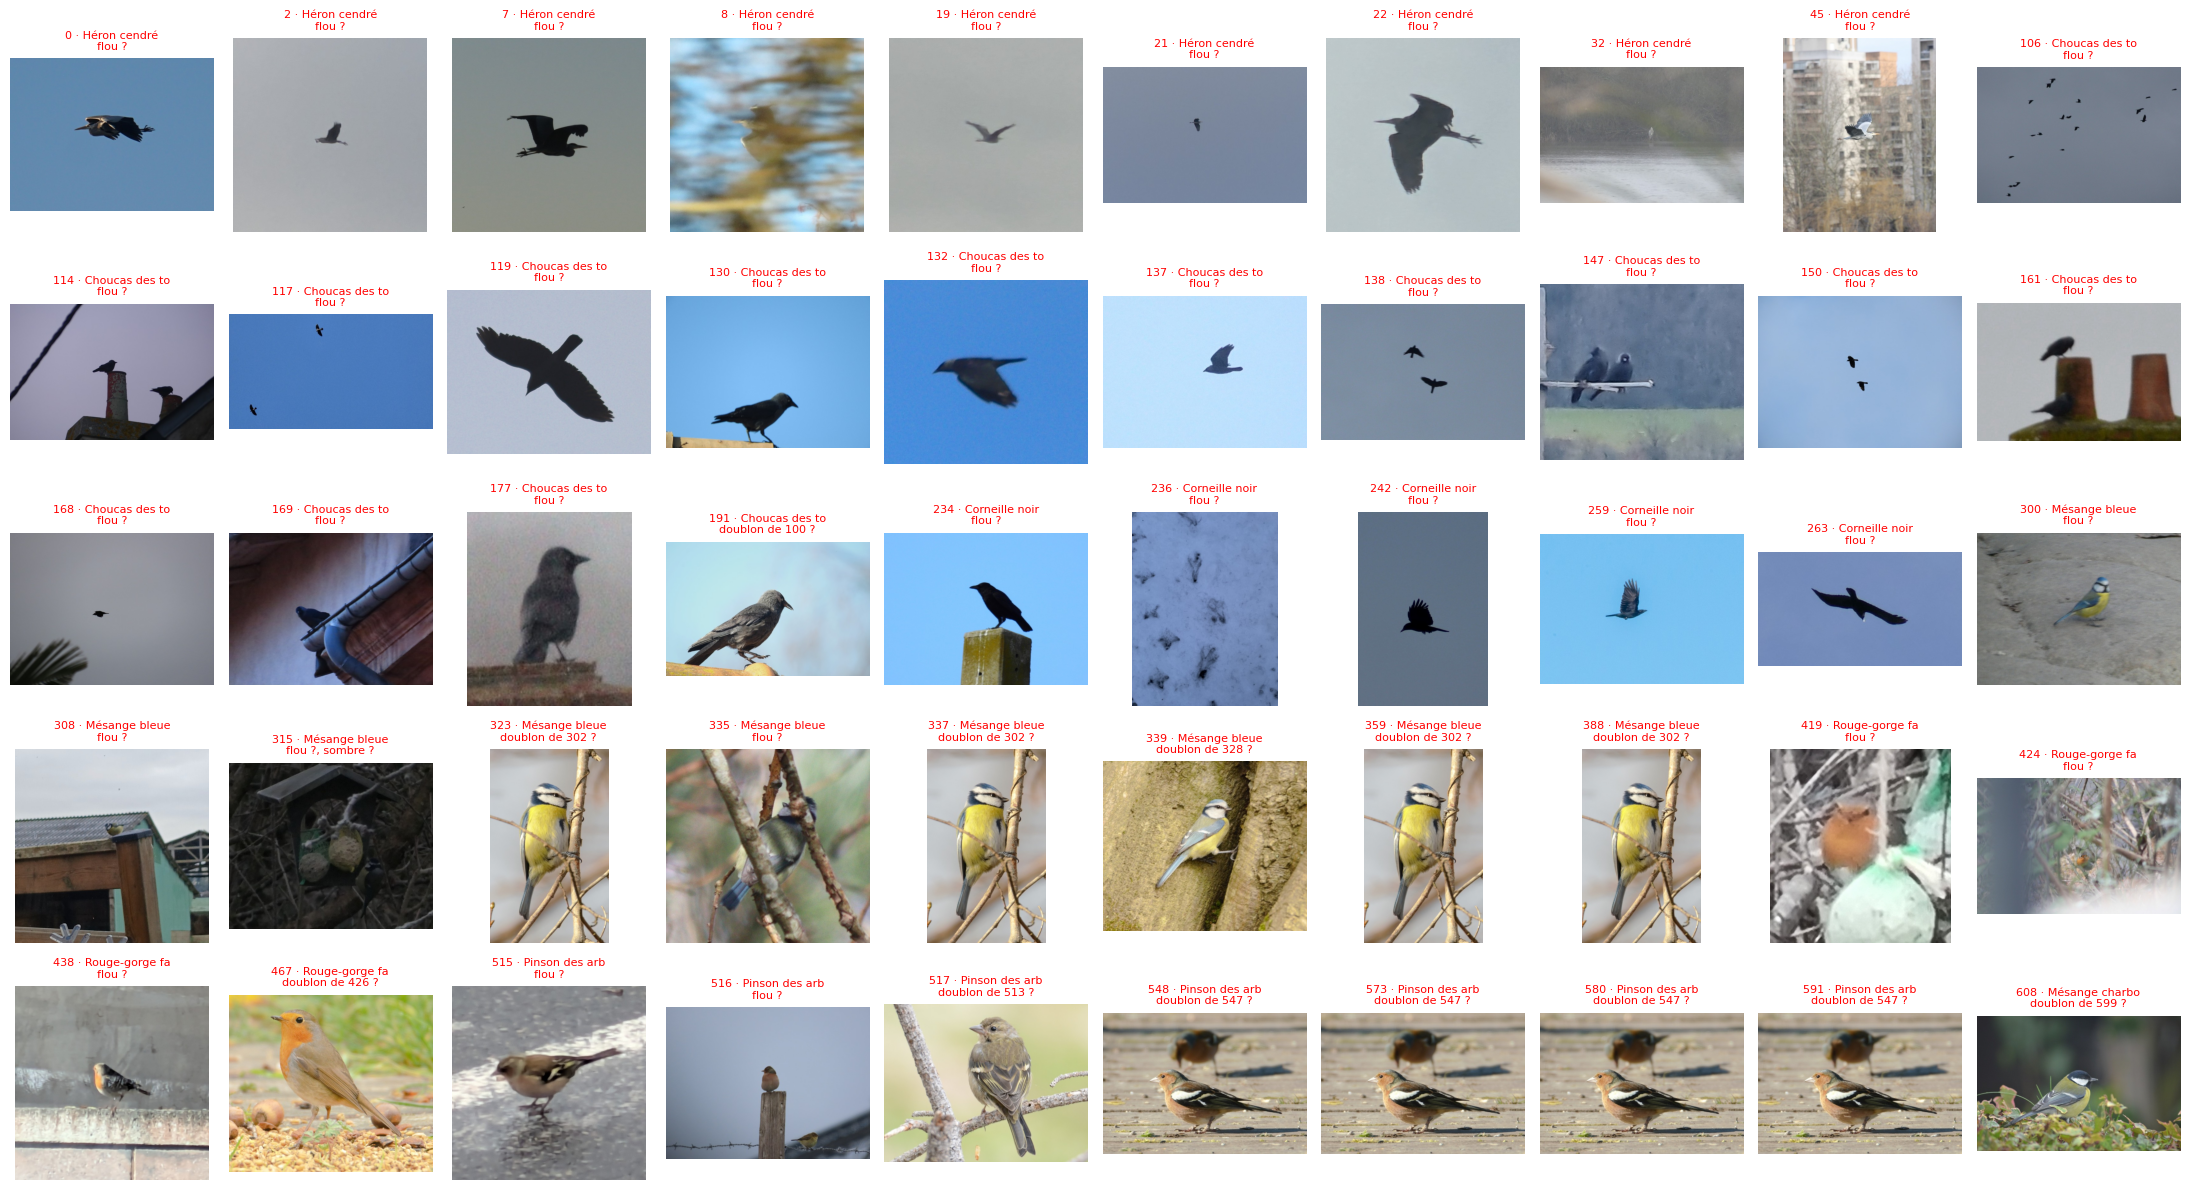

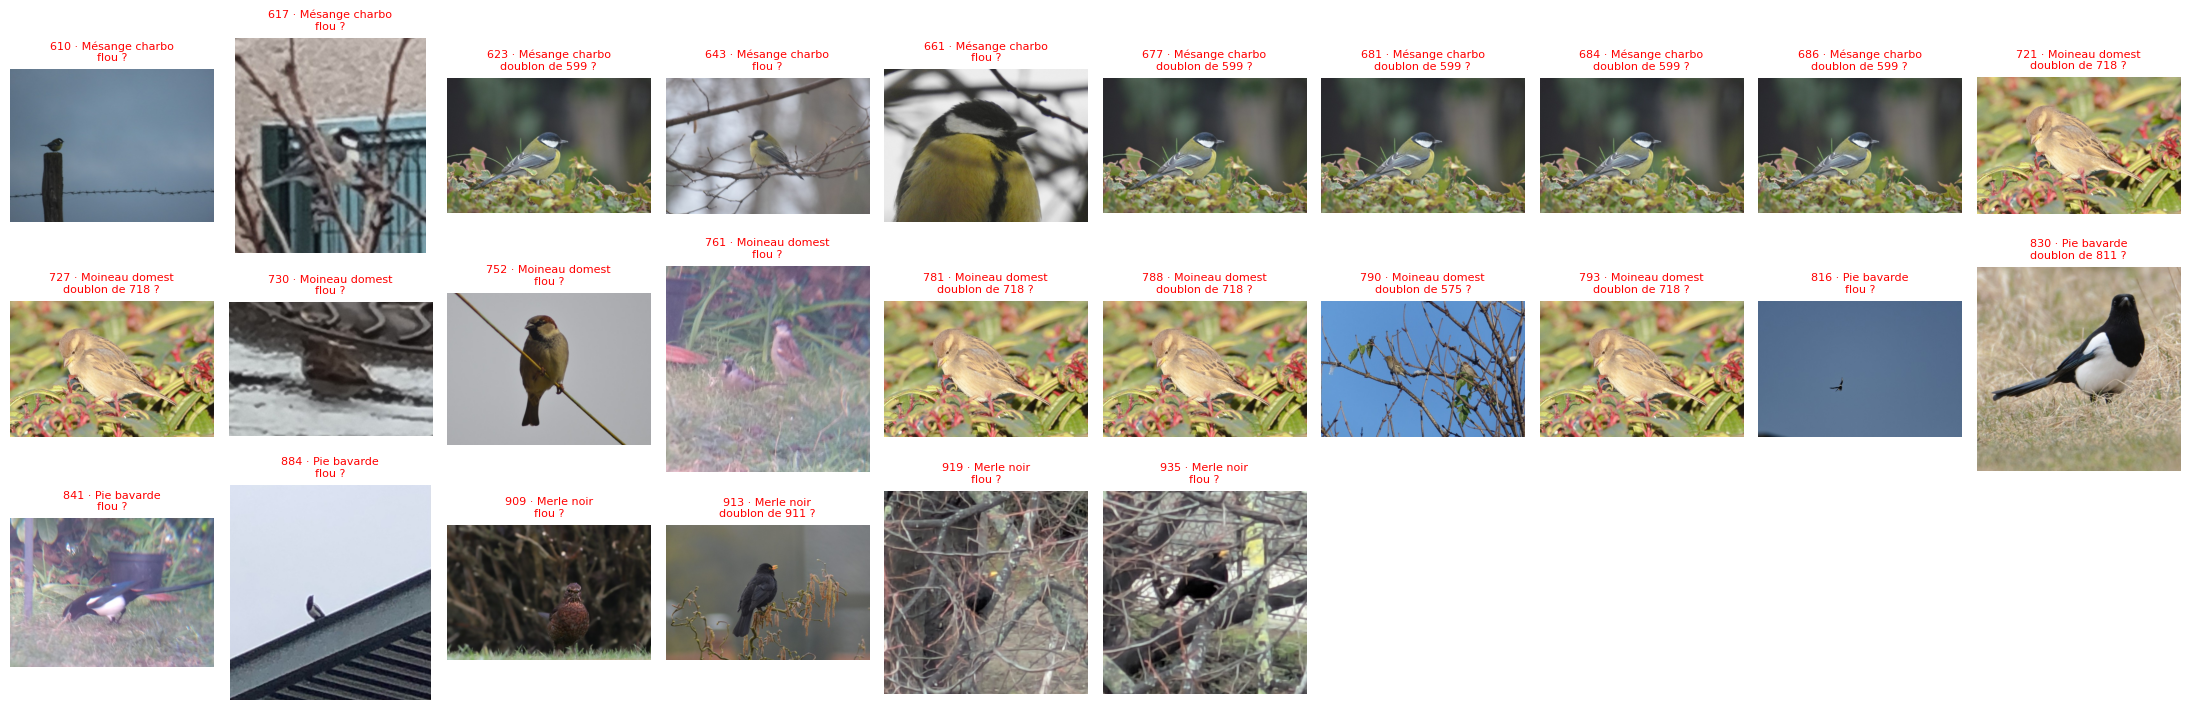

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

suspectes = meta[meta["alerte"] != ""]
print(len(suspectes), "photos à vérifier sur", len(meta))

for debut in range(0, len(suspectes), 50):
    sel = suspectes.iloc[debut:debut + 50]
    lignes = int(np.ceil(len(sel) / 10))
    fig, axes = plt.subplots(lignes, 10, figsize=(22, lignes * 2.4), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, r in zip(axes.flat, sel.itertuples()):
        ax.imshow(Image.open(r.path))
        ax.set_title(f"{r.id} · {r.french_name[:14]}\n{r.alerte}", fontsize=8, color="red")
    plt.tight_layout()
    plt.show()

affiche les photos de chaque espèce en mosaïques de 50 vignettes numérotées. Les photos signalées sont encadrées en rouge avec leur motif. Je les passe toutes en revue, pas seulement les rouge

In [13]:
# Photos en rouge que je GARDE malgré l'alerte
GARDER_QUAND_MEME = [
    # 23, 47,
]

# Photos SANS alerte que je rejette quand même
REJETS_MANUELS = {
    # 12: "pas d'oiseau",
}

meta["statut"] = "gardée"
meta["motif"] = ""

auto = (meta["alerte"] != "") & (~meta["id"].isin(GARDER_QUAND_MEME))
meta.loc[auto, "statut"] = "rejetée"
meta.loc[auto, "motif"] = meta.loc[auto, "alerte"].str.replace(" ?", "", regex=False)

for i, motif in REJETS_MANUELS.items():
    meta.loc[meta["id"] == i, ["statut", "motif"]] = ["rejetée", motif]

meta.drop(columns="path").to_csv(f"{OUT}/metadata_nettoye.csv", index=False)

print((meta["statut"] == "rejetée").sum(), "photos rejetées sur", len(meta))
display(meta.groupby(["french_name", "statut"]).size().unstack(fill_value=0))
display(meta[meta["statut"] == "rejetée"].groupby("motif").size().rename("nb_photos"))

76 photos rejetées sur 999


statut,gardée,rejetée
french_name,,
Choucas des tours,84,15
Corneille noire,95,5
Héron cendré,91,9
Merle noir,96,4
Moineau domestique,91,9
Mésange bleue,91,9
Mésange charbonnière,90,10
Pie bavarde,96,4
Pinson des arbres,93,7


,nb_photos
motif,
doublon de 100,1
doublon de 302,4
doublon de 328,1
doublon de 426,1
doublon de 513,1
doublon de 547,4
doublon de 575,1
doublon de 599,6
doublon de 718,5


Repo images propres

In [14]:
import shutil
from pathlib import Path

PROPRE = Path(OUT) / "images_propres"
if PROPRE.exists():
    shutil.rmtree(PROPRE)

gardees = meta[meta["statut"] == "gardée"]
for r in gardees.itertuples():
    dest = PROPRE / Path(r.local_path).relative_to("images")
    dest.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy(r.path, dest)

print(len(gardees), "photos copiées dans", PROPRE)
display(pd.Series({d.name: len(list(d.glob("*.jpg"))) for d in sorted(PROPRE.iterdir())}, name="nb_photos"))

923 photos copiées dans /content/drive/MyDrive/birdsfinder/data_europe_10/images_propres


,nb_photos
Ardea_cinerea,91
Coloeus_monedula,84
Corvus_corone,95
Cyanistes_caeruleus,91
Erithacus_rubecula,96
Fringilla_coelebs,93
Parus_major,90
Passer_domesticus,91
Pica_pica,96
Turdus_merula,96
